# Proyecto final · Análisis para las dos tareas de PLN

El notebook 01 describe los corpus. Este analiza los datos **desde las dos tareas del pipeline** y cada análisis termina en una decisión para una etapa concreta:

| Tarea | Papel en el pipeline | Análisis |
|---|---|---|
| **Generación de lenguaje** (principal) | BART-base recibe la oración con errores y genera la corregida | T1 destokenización · T2 copia · T3 relación de largos · T4 fragmentación BPE · T5 representatividad de los splits |
| **POS tagging** (complementaria) | spaCy etiqueta cada palabra y ERRANT usa esas etiquetas para tipar el error que explica el tutor | P1 retipado con ERRANT 3.0.2 · P2 estabilidad del etiquetado · P3 modelo de spaCy · P4 cobertura de tipos · P5 techo de la evaluación |

Cada análisis responde a uno de los requisitos de datos de Ashmore et al. (2021): **relevantes**, **completos**, **balanceados** y **precisos**. Requiere haber ejecutado antes el 01 (`make analisis` corre ambos en orden).

In [1]:
import json
import re
import subprocess
import sys
import time
from collections import Counter
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon

RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "src"))
import corpus
import texto
from graficas import AZUL, NARANJA, SECUENCIAL, TINTA_SECUNDARIA, LINEA_BASE, aplicar_estilo

CRUDOS, PROC = RAIZ / "datos" / "crudos", RAIZ / "datos" / "procesados"
FIG, RES = RAIZ / "figuras", RAIZ / "resultados"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)
aplicar_estilo()

def guardar(fig, nombre):
    fig.savefig(FIG / nombre)
    plt.show()

oraciones = pd.read_parquet(PROC / "oraciones.parquet")
ediciones = pd.read_parquet(PROC / "ediciones.parquet")
aprendices = oraciones[oraciones.corpus != "locness"].copy()
train = aprendices[aprendices.split == "train"]
print(f"{len(oraciones):,} oraciones · {len(ediciones):,} ediciones")

71,928 oraciones · 123,986 ediciones


In [2]:
import os
import warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore", message="IProgress not found")
import spacy
from transformers import AutoTokenizer

tokenizador = AutoTokenizer.from_pretrained("facebook/bart-base")
nlp_sm = spacy.load("en_core_web_sm")
bpe = lambda textos: [len(ids) for ids in tokenizador(list(textos))["input_ids"]]

# A · Generación de lenguaje

## T1 · Destokenización: ¿qué texto ve BART?

Los M2 vienen tokenizados por spaCy 1.9: `I do n't know , it 's fine .`. BART se preentrenó con texto normal y el usuario escribirá texto normal, así que conviene entrenarlo con `I don't know, it's fine.`. `src/texto.py` destokeniza con reglas para inglés. Tres mediciones:

1. **Cuántas oraciones cambian** al destokenizar, es decir, cuánto ruido de tokenización vería BART si no se hiciera.
2. **Fidelidad al texto que escribió el estudiante**: ¿la oración destokenizada aparece tal cual en el JSON original?
3. **Ida y vuelta**: destokenizar y volver a tokenizar con spaCy 3.8 (lo que hará la evaluación con la salida del modelo), ¿recupera exactamente los tokens del M2?

In [3]:
for col in ("original", "corregida"):
    aprendices[f"{col}_texto"] = aprendices[col].str.split().map(texto.destokenizar)

marcas = {
    "contracción separada (do n't, it 's)": r" (?:n't|'s|'re|'ve|'ll|'d|'m)\b",
    "espacio antes de puntuación ( , . ? !)": r" [.,!?;:]",
    "comillas con espacio interior": r'" | "',
    "guion entre palabras separado (well - known)": r"\w - \w",
}
pd.DataFrame({"% de oraciones": {k: round(100 * aprendices.original.str.contains(v).mean(), 1) for k, v in marcas.items()}})

,% de oraciones
"contracción separada (do n't, it 's)",15.3
"espacio antes de puntuación ( , . ? !)",95.1
comillas con espacio interior,2.5
guion entre palabras separado (well - known),3.3


In [4]:
crudo = {}
for _, _, _, _, ruta_json in corpus.ARCHIVOS:
    for linea in (CRUDOS / ruta_json).read_text(encoding="utf-8").splitlines():
        e = json.loads(linea)
        clave = f'{e["id"]}#{e["q"]}' if "q" in e else e["id"]
        crudo[clave] = re.sub(r"\s+", " ", e["text"].translate(corpus.NORMALIZACION))

sin_espacios = lambda s: re.sub(r"\s", "", s)
fiel = np.array([t in crudo[k] for t, k in zip(aprendices.original_texto, aprendices.texto)])
solo_espacios = np.array([not f and sin_espacios(t) in sin_espacios(crudo[k])
                          for f, t, k in zip(fiel, aprendices.original_texto, aprendices.texto)])
pd.Series({
    "idéntica al texto del estudiante": fiel.mean(),
    "difiere solo en espacios (el estudiante escribió 'certificate.I'm' o 'example,using')": solo_espacios.mean(),
    "difiere en otra cosa": 1 - fiel.mean() - solo_espacios.mean(),
}).mul(100).round(2).to_frame("% de oraciones")

,% de oraciones
idéntica al texto del estudiante,93.91
"difiere solo en espacios (el estudiante escribió 'certificate.I'm' o 'example,using')",6.09
difiere en otra cosa,0.00


In [5]:
retokenizar = lambda s: [t.text for t in nlp_sm.tokenizer(s)]
ida_vuelta = {}
diferencias = Counter()
for col in ("original", "corregida"):
    tokens = aprendices[col].str.split()
    vuelta = aprendices[f"{col}_texto"].map(retokenizar)
    iguales = np.array([a == b for a, b in zip(tokens, vuelta)])
    ida_vuelta[col] = 100 * iguales.mean()
    for a, b in zip(tokens[~iguales], vuelta[~iguales]):
        for op, i1, i2, j1, j2 in SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
            if op != "equal":
                diferencias[(" ".join(a[i1:i2]), " ".join(b[j1:j2]))] += 1
print("ida y vuelta exacta: " + " · ".join(f"{k} {v:.2f}%" for k, v in ida_vuelta.items()))
pd.DataFrame([(a, b, n) for (a, b), n in diferencias.most_common(12)], columns=["M2 (spaCy 1.9)", "spaCy 3.8", "veces"])

ida y vuelta exacta: original 99.34% · corregida 99.34%


,M2 (spaCy 1.9),spaCy 3.8,veces
0,haven't,have n't,301
1,hasn't,has n't,46
2,Mt .,Mt.,36
3,I'm,I 'm,31
4,50%,50 %,27
5,' ','',26
6,100%,100 %,20
7,20%,20 %,13
8,90%,90 %,12
9,I'll,I 'll,12


**Hallazgo.** El 95 % de las oraciones trae espacios antes de la puntuación y el 15 % contracciones partidas (`do n't`): sin destokenizar, BART se entrenaría con un inglés que nunca vio en su preentrenamiento y que el usuario nunca escribe. El destokenizador reproduce **exacto el texto del estudiante en el 93,9 %** de las oraciones; el 6,1 % restante difiere solo en espacios que el propio estudiante puso mal (*certificate.I'm*), donde la versión destokenizada es la correcta, y **0 %** difiere en otra cosa.

La ida y vuelta recupera los tokens del M2 en el 99,34 %. Lo que falla no es el destokenizador sino el cambio de versión de spaCy: la 1.9 dejaba *haven't* y *50%* en un token y la 3.8 los parte. El efecto sobre la evaluación se mide en P5.

In [6]:
aprendices["bpe_texto_max"] = np.maximum(bpe(aprendices.original_texto), bpe(aprendices.corregida_texto))
ahorro = 1 - aprendices.bpe_texto_max.sum() / aprendices.bpe_max.sum()
print(f"Tokens BPE por par: {aprendices.bpe_max.mean():.1f} tokenizado contra {aprendices.bpe_texto_max.mean():.1f} "
      f"destokenizado ({ahorro:.1%} menos) · pares de train que pasan de 128: "
      f"{(aprendices.loc[aprendices.split == 'train', 'bpe_texto_max'] > 128).sum()}")

Tokens BPE por par: 20.6 tokenizado contra 20.4 destokenizado (1.0% menos) · pares de train que pasan de 128: 28


Destokenizar casi no cambia el largo (1 % menos tokens BPE): el máximo de 128 sigue valiendo.

## T2 · ¿Cuánto copia el modelo?

En corrección gramatical la salida es casi igual a la entrada. Se mide, por par de train, qué fracción de los tokens de la oración corregida se copia tal cual de la original y cuántos tokens hay que cambiar (distancia de edición). Esto define qué debe aprender el modelo, cuánto riesgo hay de que aprenda a copiar todo y por qué la métrica es F0.5 sobre ediciones y no exactitud por token.

In [7]:
def copia_y_cambios(o, c):
    ops = SequenceMatcher(None, o, c, autojunk=False).get_opcodes()
    copiados = sum(i2 - i1 for op, i1, i2, _, _ in ops if op == "equal")
    cambios = sum(max(i2 - i1, j2 - j1) for op, i1, i2, j1, j2 in ops if op != "equal")
    return copiados / max(len(c), 1), cambios

pares = aprendices[aprendices.split == "train"]
medidas = [copia_y_cambios(o.split(), c.split()) for o, c in zip(pares.original, pares.corregida)]
pares = pares.assign(copia=[m[0] for m in medidas], cambios=[m[1] for m in medidas])
cambian = pares[pares.original != pares.corregida]
pd.Series({
    "pares idénticos (no hay nada que cambiar)": f"{100 * (pares.original == pares.corregida).mean():.1f}%",
    "tokens copiados, en los pares que cambian (media)": f"{100 * cambian.copia.mean():.1f}%",
    "tokens copiados, en los pares que cambian (p10)": f"{100 * cambian.copia.quantile(0.1):.1f}%",
    "tokens a cambiar por par que cambia (mediana)": f"{cambian.cambios.median():.0f}",
    "tokens copiados en todo train": f"{100 * (pares.copia * pares.corregida.str.split().str.len()).sum() / pares.corregida.str.split().str.len().sum():.1f}%",
}).to_frame("valor")

,valor
pares idénticos (no hay nada que cambiar),35.4%
"tokens copiados, en los pares que cambian (media)",86.0%
"tokens copiados, en los pares que cambian (p10)",72.7%
tokens a cambiar por par que cambia (mediana),2
tokens copiados en todo train,90.1%


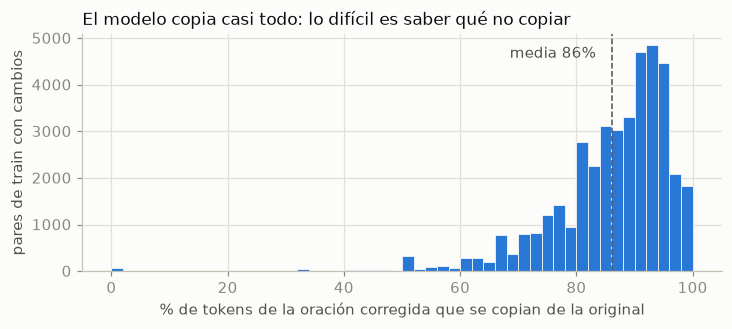

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.hist(100 * cambian.copia, bins=np.arange(0, 102, 2), color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
media = 100 * cambian.copia.mean()
ax.axvline(media, color=TINTA_SECUNDARIA, linewidth=1, linestyle="--")
ax.text(media - 1, ax.get_ylim()[1] * 0.9, f"media {media:.0f}%  ", color=TINTA_SECUNDARIA, ha="right")
ax.set_xlabel("% de tokens de la oración corregida que se copian de la original")
ax.set_ylabel("pares de train con cambios")
ax.set_title("El modelo copia casi todo: lo difícil es saber qué no copiar")
guardar(fig, "07_copia.png")

**Hallazgo.** El 35,4 % de los pares no cambia nada y, en los que cambian, el 86 % de los tokens se copia tal cual; en todo train se copia el 90 %. La mediana es de 2 tokens a cambiar por oración. Dos consecuencias:

- Un sistema que no corrige nada acertaría el 90 % de los tokens: **la exactitud por token no sirve como métrica**. F0.5 sobre ediciones (P5) da 0 a ese sistema.
- El riesgo de BART no es inventar texto sino **corregir de menos**. F0.5 pesa más la precisión, lo que es deseable para un tutor (una corrección falsa confunde más que una omitida), pero conviene vigilar el recall al afinar.

## T3 · Relación de largos entre corregida y original

Si la corrección rara vez alarga mucho la oración, el largo máximo de generación puede ser el mismo de la entrada (128). Los pares con una relación extrema, con oraciones de 5 tokens o más, son candidatos a alineaciones rotas.

In [9]:
con_texto = aprendices[aprendices.n_tokens > 0]
razon = con_texto.corregida.str.split().str.len() / con_texto.n_tokens
razon_bpe = (np.array(bpe(con_texto.corregida_texto)) / np.array(bpe(con_texto.original_texto)))
print("razón de largos en tokens, percentiles 0,1 / 1 / 50 / 99 / 99,9:",
      np.percentile(razon, [0.1, 1, 50, 99, 99.9]).round(2))
print("razón en tokens BPE, p99,9:", np.percentile(razon_bpe, 99.9).round(2))
extremos = con_texto[(con_texto.n_tokens >= 5) & ((razon < 0.5) | (razon > 2))]
print(f"pares extremos (≥ 5 tokens y razón < 0,5 o > 2): {len(extremos)} "
      f"({100 * len(extremos) / len(con_texto):.2f}%), en train: {(extremos.split == 'train').sum()}")
extremos.assign(razon=razon[extremos.index].round(2))[["corpus", "split", "razon", "original_texto", "corregida_texto"]].head(8)

razón de largos en tokens, percentiles 0,1 / 1 / 50 / 99 / 99,9: [0.67 0.84 1.   1.25 1.5 ]
razón en tokens BPE, p99,9: 1.33
pares extremos (≥ 5 tokens y razón < 0,5 o > 2): 3 (0.00%), en train: 1


,corpus,split,razon,original_texto,corregida_texto
37991,wi,train,2.4,purpose score most points.,The aim of the game is to score the most points.
68953,wi,dev,0.0,"However, information which is appeared on Facebook or Twitter are easily accessible, therefore everybody can easily response as a public...",
69117,wi,dev,0.0,"non-standard situations, analyzing the problem, finding and implementing practical and easy solutions.",


**Hallazgo.** La corrección casi no cambia el largo: la mediana de la razón es 1, el 99,9 % queda por debajo de 1,5 en tokens y de 1,33 en BPE. Con entradas de hasta 128 tokens BPE, **128 también alcanza para generar**. Solo hay 3 pares extremos y son legítimos (una reescritura completa y dos fragmentos que el anotador borró), así que no se filtra nada.

## T4 · Fragmentación BPE de las palabras mal escritas

BART usa BPE a nivel de byte: ninguna palabra queda como desconocida, pero una palabra mal escrita se parte en más piezas. Se comparan las ediciones `R:SPELL` de una sola palabra (*everithing* → *everything*), tokenizando cada palabra como aparece dentro de una oración (con espacio delante).

In [10]:
ortografia = ediciones[(ediciones.tipo == "R:SPELL")
                       & ediciones.original.str.fullmatch(r"[A-Za-z]+")
                       & ediciones.correccion.str.fullmatch(r"[A-Za-z]+")]
piezas = lambda palabras: [len(ids) for ids in tokenizador([" " + p for p in palabras], add_special_tokens=False)["input_ids"]]
frag = pd.DataFrame({"mal escrita": piezas(ortografia.original), "corregida": piezas(ortografia.correccion)})
desconocidos = sum(ids.count(tokenizador.unk_token_id) for ids in tokenizador(list(aprendices.original_texto))["input_ids"])
print(f"{len(frag):,} errores de ortografía · piezas por palabra: {frag['mal escrita'].mean():.2f} mal escrita "
      f"contra {frag['corregida'].mean():.2f} corregida · tokens <unk> en todo el corpus: {desconocidos}")
ejemplos = ortografia.sample(6, random_state=2)
pd.DataFrame({"mal escrita": ejemplos.original.values, "piezas": [tokenizador.tokenize(" " + p) for p in ejemplos.original],
              "corregida": ejemplos.correccion.values, "piezas ": [tokenizador.tokenize(" " + p) for p in ejemplos.correccion]})

7,796 errores de ortografía · piezas por palabra: 2.52 mal escrita contra 1.11 corregida · tokens <unk> en todo el corpus: 0


,mal escrita,piezas,corregida,piezas
0,bussiness,"[Ġb, uss, iness]",business,[Ġbusiness]
1,wiill,"[Ġwi, ill]",will,[Ġwill]
2,suprised,"[Ġsu, pr, ised]",surprised,[Ġsurprised]
3,greatful,"[Ġgreat, ful]",great,[Ġgreat]
4,emocional,"[Ġem, oc, ional]",emotional,[Ġemotional]
5,kindergarden,"[Ġkinderg, arden]",kindergarten,[Ġkindergarten]


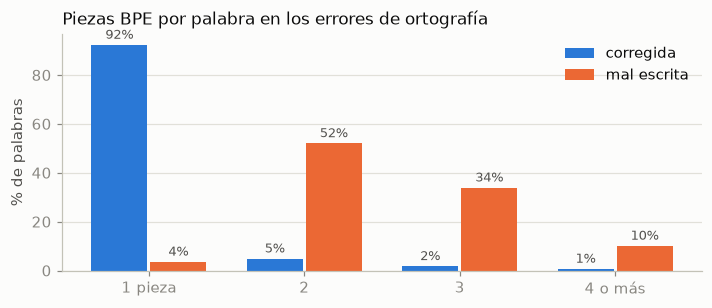

In [11]:
cubos = lambda s: s.clip(upper=4).value_counts(normalize=True).reindex([1, 2, 3, 4], fill_value=0) * 100
dist = pd.DataFrame({"corregida": cubos(frag["corregida"]), "mal escrita": cubos(frag["mal escrita"])})
fig, ax = plt.subplots(figsize=(7.5, 2.8))
x = np.arange(4)
for k, (col, color) in enumerate([("corregida", AZUL), ("mal escrita", NARANJA)]):
    barras = ax.bar(x + (k - 0.5) * 0.38, dist[col], width=0.36, color=color, label=col)
    ax.bar_label(barras, fmt="%.0f%%", padding=2, color=TINTA_SECUNDARIA, fontsize=8.5)
ax.set_xticks(x, ["1 pieza", "2", "3", "4 o más"]); ax.grid(axis="x", visible=False)
ax.set_ylabel("% de palabras"); ax.set_title("Piezas BPE por palabra en los errores de ortografía")
ax.legend(frameon=False)
guardar(fig, "08_bpe_ortografia.png")

**Hallazgo.** El BPE a nivel de byte no deja ningún token desconocido en todo el corpus, pero una palabra mal escrita se parte en 2,5 piezas en promedio contra 1,1 de la correcta (*bussiness* → `b`·`uss`·`iness`, *business* → una pieza). Para el modelo, corregir ortografía es reconocer una secuencia rara de piezas y reemplazarla por una pieza frecuente: el tokenizador de BART sirve tal cual y no hace falta un vocabulario propio.

## T5 · ¿Dev y test se parecen a train?

Si la distribución de categorías de error de dev o test es muy distinta a la de train, el F0.5 mide otra cosa. Cada split se compara con el train **de su mismo corpus** con la divergencia de Jensen–Shannon (0 = idénticas, 1 = sin nada en común), y esa divergencia se contrasta con la que da una **muestra al azar del train del mismo tamaño** (300 repeticiones): si el split queda dentro de ese rango, no se distingue de train más allá del azar. La última fila es una referencia: cuánto difieren FCE y W&I entre sí.

In [12]:
oro = ediciones[(ediciones.corpus != "locness") & (ediciones.tipo != "UNK")]
categorias = sorted(oro.categoria.unique())
distribucion = lambda e: e.categoria.value_counts().reindex(categorias, fill_value=0).values
sel = lambda corpus, split, l1=None: oro[(oro.corpus == corpus) & (oro.split == split) & (oro.l1.eq(l1) if l1 else True)]
comparaciones = {
    "dev FCE → train FCE": (sel("fce", "dev"), sel("fce", "train")),
    "dev W&I → train W&I": (sel("wi", "dev"), sel("wi", "train")),
    "test FCE → train FCE": (sel("fce", "test"), sel("fce", "train")),
    "test FCE · es → train FCE · es": (sel("fce", "test", "es"), sel("fce", "train", "es")),
    "referencia: train W&I → train FCE": (sel("wi", "train"), sel("fce", "train")),
}
rng = np.random.default_rng(0)
filas = []
for nombre, (e, ref) in comparaciones.items():
    p_ref = distribucion(ref)
    azar = [jensenshannon(p_ref, distribucion(ref.iloc[rng.choice(len(ref), len(e), replace=len(e) > len(ref))]), base=2)
            for _ in range(300)]
    filas.append({"comparación": nombre, "ediciones": len(e), "JSD contra train": jensenshannon(p_ref, distribucion(e), base=2),
                  "azar p95": np.percentile(azar, 95)})
jsd = pd.DataFrame(filas).set_index("comparación")
jsd["dentro del azar"] = jsd["JSD contra train"] <= jsd["azar p95"]
jsd.round(4).to_csv(RES / "representatividad_splits.csv")
jsd.round(4)

,ediciones,JSD contra train,azar p95,dentro del azar
comparación,,,,
dev FCE → train FCE,3421,0.0371,0.0422,True
dev W&I → train W&I,6532,0.0264,0.0288,True
test FCE → train FCE,4549,0.0841,0.0355,False
test FCE · es → train FCE · es,612,0.2148,0.1032,False
referencia: train W&I → train FCE,62034,0.1577,0.0102,False


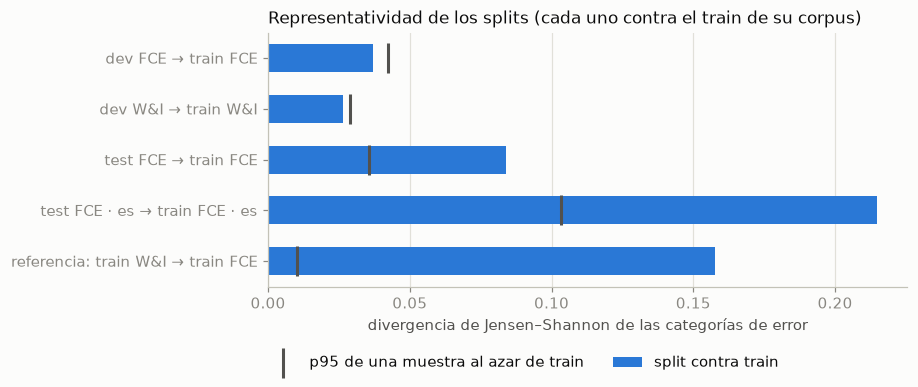

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3))
y = np.arange(len(jsd))
ax.barh(y, jsd["JSD contra train"], color=AZUL, height=0.55, label="split contra train")
ax.scatter(jsd["azar p95"], y, marker="|", s=400, color=TINTA_SECUNDARIA, linewidths=2, label="p95 de una muestra al azar de train", zorder=3)
ax.set_yticks(y, jsd.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("divergencia de Jensen–Shannon de las categorías de error")
ax.set_title("Representatividad de los splits (cada uno contra el train de su corpus)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.22), ncol=2)
guardar(fig, "09_representatividad_splits.png")

**Hallazgo.** Los dos dev se parecen a su train dentro de lo esperable por azar, así que sirven para elegir checkpoint. **El test de FCE no**: difiere de train más del doble que una muestra al azar. Según el id de cada texto, train y dev son exámenes del año **2000** y test del **2001**: otra sesión, con otras preguntas, más errores por token (11,4 contra 9,8 por cada 100), más errores de artículos y de mayúsculas y menos de verbos. No es un defecto: es el split oficial de BEA-2019 y se mantiene para poder comparar con la literatura, pero el F0.5 en test será **más bajo que en dev** y el documento debe explicarlo como una prueba de generalización a otra sesión del examen. Como referencia, FCE y W&I difieren entre sí 0,158: más que cualquier split.

# B · POS tagging

ERRANT alinea la oración original con la corregida y clasifica cada edición con las **etiquetas POS y los lemas de spaCy**: si *help* pasa a *helped* (mismo lema, otra forma), es `VERB:FORM`. Ese tipo es el que elige la explicación del tutor. Todo depende de que spaCy etiquete bien un texto **con errores**, para el que no fue entrenado.

Se etiquetan todas las oraciones con error con dos modelos: `en_core_web_sm` (el que ERRANT usa por defecto) y `en_core_web_lg` (misma arquitectura con vectores de palabra grandes).

In [14]:
import errant
from spacy.tokens import Doc

modelos = {"sm": nlp_sm, "lg": spacy.load("en_core_web_lg")}
anotadores = {k: errant.load("en", nlp) for k, nlp in modelos.items()}
con_error = aprendices[aprendices.n_ediciones > 0]
docs, velocidad = {}, {}
for k, nlp in modelos.items():
    inicio = time.time()
    analizar = lambda col: list(nlp.pipe((Doc(nlp.vocab, words=t.split()) for t in con_error[col]), batch_size=512))
    docs[k] = dict(zip(con_error.id, zip(analizar("original"), analizar("corregida"))))
    velocidad[k] = 2 * len(con_error) / (time.time() - inicio)
print(f"{len(con_error):,} oraciones con error · " + " · ".join(f"{k}: {v:,.0f} oraciones/s" for k, v in velocidad.items()))

46,654 oraciones con error · sm: 1,006 oraciones/s · lg: 937 oraciones/s


## P1 · Retipar las ediciones con ERRANT 3.0.2

Se conservan los spans anotados y solo se vuelve a clasificar cada edición (`import_edit`), con cada modelo. Así el tipo de cada error del corpus queda en el mismo sistema que usará el tutor para explicar las correcciones del modelo.

In [15]:
por_oracion = {i: g.sort_values(["inicio", "fin"], kind="stable")
               for i, g in ediciones[ediciones.id_oracion.isin(con_error.id)].groupby("id_oracion")}
filas, spans = [], {}
for id_oracion, eds in por_oracion.items():
    posiciones = corpus.posiciones_en_corregida(
        [corpus.Edicion(e.inicio, e.fin, e.tipo, e.correccion, 0) for e in eds.itertuples()])
    spans[id_oracion] = [(e.inicio, e.fin, cs, ce) for e, (cs, ce) in zip(eds.itertuples(), posiciones)]
    for e, (cs, ce) in zip(eds.itertuples(), posiciones):
        if e.tipo == "UNK":
            continue
        fila = {"id_oracion": id_oracion, "split": e.split, "l1": e.l1, "tipo_oro": e.tipo}
        for k, anotador in anotadores.items():
            o, c = docs[k][id_oracion]
            fila[f"tipo_{k}"] = anotador.import_edit(o, c, [e.inicio, e.fin, cs, ce], min=False).type
        filas.append(fila)
tipos = pd.DataFrame(filas)
for k in modelos:
    tipos[f"cat_{k}"] = tipos[f"tipo_{k}"].str.split(":", n=1).str[1].fillna(tipos[f"tipo_{k}"])
tipos["cat_oro"] = tipos.tipo_oro.str.split(":", n=1).str[1]
print(f"{len(tipos):,} ediciones retipadas · mismo tipo que el oro: "
      + " · ".join(f"{k} {100 * (tipos.tipo_oro == tipos[f'tipo_{k}']).mean():.1f}%" for k in modelos))
(tipos[tipos.tipo_oro != tipos.tipo_sm].groupby(["tipo_oro", "tipo_sm"]).size()
 .nlargest(12).rename("ediciones").reset_index().rename(columns={"tipo_oro": "oro (M2)", "tipo_sm": "ERRANT 3.0.2 · sm"}))

119,587 ediciones retipadas · mismo tipo que el oro: sm 94.8% · lg 94.8%


,oro (M2),ERRANT 3.0.2 · sm,ediciones
0,R:OTHER,R:SPELL,1029
1,R:OTHER,R:PRON,456
2,R:NOUN:NUM,R:MORPH,380
3,R:OTHER,R:VERB,286
4,R:OTHER,R:DET,231
5,R:OTHER,R:PREP,226
6,R:OTHER,R:ADJ,223
7,R:OTHER,R:NOUN,206
8,R:OTHER,R:ADV,205
9,R:NOUN:INFL,R:SPELL,146


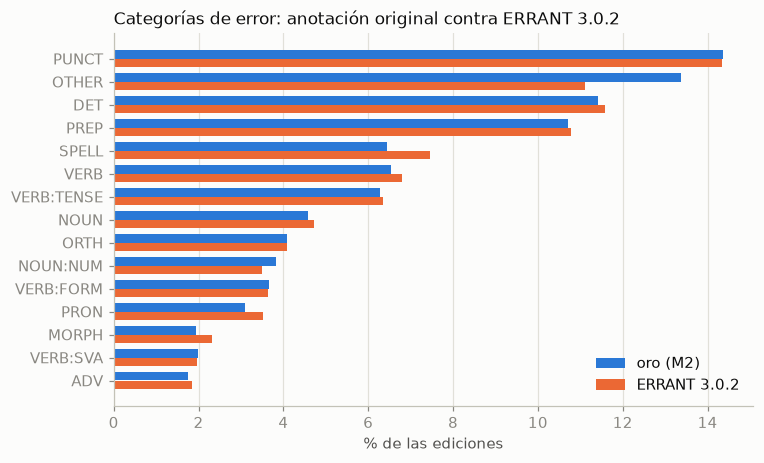

In [16]:
participacion = pd.DataFrame({
    "oro (M2)": tipos.cat_oro.value_counts(normalize=True),
    "ERRANT 3.0.2": tipos.cat_sm.value_counts(normalize=True),
}).fillna(0).mul(100)
participacion = participacion.loc[participacion.max(axis=1).nlargest(15).index]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
y = np.arange(len(participacion))
for k, (col, color) in enumerate([("oro (M2)", AZUL), ("ERRANT 3.0.2", NARANJA)]):
    ax.barh(y + (k - 0.5) * 0.38, participacion[col], height=0.36, color=color, label=col)
ax.set_yticks(y, participacion.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("% de las ediciones"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Categorías de error: anotación original contra ERRANT 3.0.2")
guardar(fig, "10_tipos_retipados.png")

**Hallazgo.** ERRANT 3.0.2 asigna el mismo tipo que la anotación original al 94,8 % de las ediciones, con `sm` y con `lg`. Casi todos los cambios salen de `R:OTHER` hacia un tipo concreto (1.029 a `R:SPELL`, 456 a `R:PRON`, 286 a `R:VERB`...) y de categorías de forma (`NOUN:NUM`, `ADJ:FORM`) a `MORPH`. Las ediciones sin categoría útil (`*:OTHER`) bajan de 13,4 % a 11,1 %: **retipar le da al tutor algo concreto que explicar en 2.700 ediciones más**.

## P2 · ¿Qué tan estable es el etiquetado en texto con errores?

No hay etiquetas POS de referencia para textos de aprendices, pero hay un control natural: una palabra que **no se editó** debería recibir la misma etiqueta en la oración original y en la corregida. Si cambia, el error vecino confundió al etiquetador, y una etiqueta equivocada puede producir un tipo de error equivocado. Se mide por distancia a la edición más cercana.

In [17]:
# Tokens hasta la edición más cercana: 1 = pegado a ella. Una inserción en s queda entre s-1 y s
def distancia(i, eds):
    return min(s - i if i < s else i - max(e, s) + 1 for s, e, _, _ in eds)

filas = []
for id_oracion, eds in spans.items():
    editados = {i for s, e, _, _ in eds for i in range(s, e)}
    resultados = {k: docs[k][id_oracion] for k in modelos}
    n = len(resultados["sm"][0])
    for i in range(n):
        if i in editados:
            continue
        # Posición en la corregida: se corre lo que sumaron o quitaron las ediciones anteriores
        j = i + sum((ce - cs) - (e - s) for s, e, cs, ce in eds if e <= i)
        fila = {"distancia": distancia(i, eds)}
        for k, (o, c) in resultados.items():
            fila[f"cambia_{k}"] = o[i].pos_ != c[j].pos_
            fila[f"mismo_texto_{k}"] = o[i].text == c[j].text
        filas.append(fila)
estab = pd.DataFrame(filas)
print(f"tokens no editados comparados: {len(estab):,} · alineados al mismo texto: {estab.mismo_texto_sm.mean():.2%}")
estab["tramo"] = pd.cut(estab.distancia, [0, 1, 2, 5, 1000], labels=["junto al error", "a 2", "a 3-5", "a 6 o más"])
por_tramo = estab.groupby("tramo", observed=True)[[f"cambia_{k}" for k in modelos]].mean().mul(100).round(2)
por_tramo.columns = [f"% cambia POS · {k}" for k in modelos]
por_tramo

tokens no editados comparados: 827,488 · alineados al mismo texto: 100.00%


,% cambia POS · sm,% cambia POS · lg
tramo,,
junto al error,2.89,2.78
a 2,0.59,0.52
a 3-5,0.10,0.09
a 6 o más,0.01,0.01


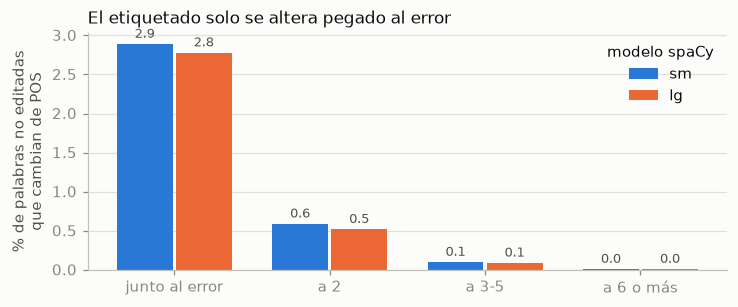

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
x = np.arange(len(por_tramo))
for k, (col, color) in enumerate(zip(por_tramo.columns, [AZUL, NARANJA])):
    barras = ax.bar(x + (k - 0.5) * 0.38, por_tramo[col], width=0.36, color=color, label=col.split("· ")[1])
    ax.bar_label(barras, fmt="%.1f", padding=2, color=TINTA_SECUNDARIA, fontsize=8.5)
ax.set_xticks(x, por_tramo.index); ax.grid(axis="x", visible=False)
ax.set_ylabel("% de palabras no editadas\nque cambian de POS"); ax.legend(frameon=False, title="modelo spaCy")
ax.set_title("El etiquetado solo se altera pegado al error")
guardar(fig, "11_estabilidad_pos.png")

**Hallazgo.** El etiquetado es robusto: de 827 mil palabras no editadas, solo el 0,8 % cambia de POS entre la oración original y la corregida, y el efecto se concentra pegado al error (2,9 %) y desaparece a 3 palabras o más (0,1 %). Es una cota superior, porque a veces la corrección cambia legítimamente la función de la palabra vecina (*that* pasa de determinante a conjunción). **El tipo que asigna ERRANT es confiable** y no hace falta una capa de advertencias en la explicación.

## P3 · ¿`en_core_web_sm` o `en_core_web_lg`?

Criterio principal: estabilidad del etiquetado (P2), porque mide robustez al texto con errores. Secundarios: acuerdo con el tipo anotado, cuántas ediciones quedan en una categoría `OTHER` (que no permite explicar nada concreto) y velocidad.

In [19]:
comparacion = pd.DataFrame({k: {
    "% palabras no editadas que cambian de POS": 100 * estab[f"cambia_{k}"].mean(),
    "% que cambian junto al error": 100 * estab.loc[estab.distancia == 1, f"cambia_{k}"].mean(),
    "% mismo tipo que el oro": 100 * (tipos.tipo_oro == tipos[f"tipo_{k}"]).mean(),
    "% ediciones en *:OTHER": 100 * tipos[f"tipo_{k}"].str.endswith("OTHER").mean(),
    "oraciones por segundo": velocidad[k],
} for k in modelos}).round(2)
comparacion["oro (M2)"] = [np.nan, np.nan, 100.0, round(100 * tipos.tipo_oro.str.endswith("OTHER").mean(), 2), np.nan]
mejora = comparacion.loc["% palabras no editadas que cambian de POS", "sm"] - comparacion.loc["% palabras no editadas que cambian de POS", "lg"]
ELEGIDO = "lg" if mejora >= 0.5 else "sm"
print(f"lg reduce la inestabilidad en {mejora:.2f} puntos → modelo elegido para tipar y explicar: en_core_web_{ELEGIDO}")
comparacion.to_csv(RES / "comparacion_spacy.csv")
comparacion

lg reduce la inestabilidad en 0.04 puntos → modelo elegido para tipar y explicar: en_core_web_sm


,sm,lg,oro (M2)
% palabras no editadas que cambian de POS,0.80,0.76,NaN
% que cambian junto al error,2.89,2.78,NaN
% mismo tipo que el oro,94.78,94.80,100.00
% ediciones en *:OTHER,11.11,11.09,13.37
oraciones por segundo,1005.50,937.01,NaN


**Hallazgo.** `en_core_web_lg` no mejora a `sm` de forma apreciable (0,04 puntos de estabilidad, mismo acuerdo de tipo, mismo % de `OTHER`) y es algo más lento y pesa 400 MB más. Se queda **`en_core_web_sm`**, que además es el que usa la evaluación oficial: el tutor explica con los mismos tipos con los que se evalúa.

## P4 · ¿Cuántas explicaciones hay que escribir?

El tutor explica cada error según su tipo. Con los tipos del modelo elegido, ¿cuántos tipos (operación + categoría) y cuántas categorías cubren el 80, 90 y 95 % de las ediciones?

In [20]:
def cuantos_para(serie, umbrales=(80, 90, 95)):
    acumulado = serie.value_counts(normalize=True).cumsum() * 100
    return {f"{u}%": int((acumulado < u).sum() + 1) for u in umbrales}, acumulado

n_tipos, acum_tipos = cuantos_para(tipos[f"tipo_{ELEGIDO}"])
n_cats, acum_cats = cuantos_para(tipos[f"cat_{ELEGIDO}"])
cobertura_tipos = pd.DataFrame({"tipos (operación + categoría)": n_tipos, "categorías": n_cats}).T
cobertura_tipos["total distintos"] = [tipos[f"tipo_{ELEGIDO}"].nunique(), tipos[f"cat_{ELEGIDO}"].nunique()]
cobertura_tipos.to_csv(RES / "cobertura_tipos.csv")
cobertura_tipos

,80%,90%,95%,total distintos
tipos (operación + categoría),18,25,32,55
categorías,10,13,16,25


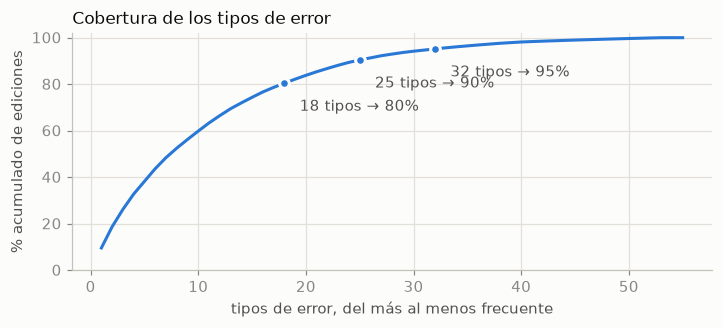

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
x = np.arange(1, len(acum_tipos) + 1)
ax.plot(x, acum_tipos.values, color=AZUL, linewidth=2)
for u, n in n_tipos.items():
    v = acum_tipos.values[n - 1]
    ax.scatter([n], [v], color=AZUL, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=2)
    ax.annotate(f"{n} tipos → {u}", (n, v), textcoords="offset points", xytext=(10, -18), color=TINTA_SECUNDARIA)
ax.set_xlabel("tipos de error, del más al menos frecuente"); ax.set_ylabel("% acumulado de ediciones")
ax.set_ylim(0, 102); ax.set_title("Cobertura de los tipos de error")
guardar(fig, "12_cobertura_tipos.png")

**Hallazgo.** De 55 tipos distintos, **18 cubren el 80 %** de las ediciones y 25 el 90 %; en categorías, 10 y 13 de 25. Plan para la explicación: plantillas escritas a mano para los 25 tipos del 90 % (abajo, los del 80 %) y una explicación genérica por operación (*falta*, *sobra*, *cambia*) para el resto.

In [22]:
(tipos[f"tipo_{ELEGIDO}"].value_counts(normalize=True).mul(100).round(1).head(n_tipos["80%"])
 .rename("% de ediciones").to_frame().T)

tipo_sm,M:PUNCT,R:OTHER,R:SPELL,R:PREP,R:VERB,M:DET,R:VERB:TENSE,R:ORTH,R:NOUN,U:DET,R:NOUN:NUM,R:PUNCT,R:VERB:FORM,R:DET,M:PREP,R:MORPH,R:VERB:SVA,U:PREP
% de ediciones,9.6,9.1,7.5,6.6,5.5,5.4,4.8,4.1,3.7,3.6,3.5,3.1,3.0,2.5,2.4,2.3,2.0,1.8


## P5 · Techo de la evaluación

La evaluación oficial (BEA-2019) toma la oración original y la salida del sistema, extrae las ediciones con `errant_parallel` y las compara con el M2 de referencia con `errant_compare` (las `UNK` no cuentan). Antes de entrenar se prueba ese circuito con salidas **conocidas** sobre FCE test:

- **copiar la entrada**: un sistema que no corrige nada (piso);
- **referencia en tokens del M2**: la respuesta correcta, con la tokenización original (techo de ERRANT 3.0.2 frente a las anotaciones);
- **referencia destokenizada → spaCy 3.8**: la respuesta correcta pasada por el mismo camino que seguirá la salida de BART (techo real del pipeline).

Se usa el ERRANT por defecto (`sm`), como en BEA-2019, para que los números sean comparables con la literatura.

In [23]:
EVAL = PROC / "evaluacion"
EVAL.mkdir(exist_ok=True)
REF_M2 = CRUDOS / "fce" / "m2" / "fce.test.gold.bea19.m2"
test = aprendices[(aprendices.corpus == "fce") & (aprendices.split == "test")].sort_values("id")
bloques = REF_M2.read_text(encoding="utf-8").strip().split("\n\n")
assert len(bloques) == len(test)

def evaluar(nombre, hipotesis, filtro=None):
    sel = np.ones(len(test), bool) if filtro is None else np.asarray(filtro)
    (EVAL / "orig.txt").write_text("\n".join(test.original[sel]) + "\n")
    (EVAL / "hip.txt").write_text("\n".join(np.asarray(hipotesis)[sel]) + "\n")
    (EVAL / "ref.m2").write_text("\n\n".join(b for b, s in zip(bloques, sel) if s) + "\n\n")
    subprocess.run(["errant_parallel", "-orig", EVAL / "orig.txt", "-cor", EVAL / "hip.txt", "-out", EVAL / "hip.m2"],
                   check=True, capture_output=True)
    salida = subprocess.run(["errant_compare", "-hyp", EVAL / "hip.m2", "-ref", EVAL / "ref.m2"],
                            check=True, capture_output=True, text=True).stdout.split()
    i = salida.index("F0.5") + 1
    tp, fp, fn, p, r, f = salida[i:i + 6]
    return {"escenario": nombre, "TP": int(tp), "FP": int(fp), "FN": int(fn), "P": float(p), "R": float(r), "F0.5": float(f)}

es = test.l1.eq("es").values
destok = [" ".join(retokenizar(t)) for t in test.corregida_texto]
techo = pd.DataFrame([
    evaluar("copiar la entrada", test.original),
    evaluar("referencia en tokens del M2", test.corregida),
    evaluar("referencia destokenizada → spaCy 3.8", destok),
    evaluar("referencia destokenizada → spaCy 3.8 · solo es", destok, es),
]).set_index("escenario")
techo.to_csv(RES / "techo_evaluacion.csv")
techo

,TP,FP,FN,P,R,F0.5
escenario,,,,,,
copiar la entrada,0,0,4549,1.0000,0.0000,0.0000
referencia en tokens del M2,3936,670,613,0.8545,0.8652,0.8567
referencia destokenizada → spaCy 3.8,3933,682,616,0.8522,0.8646,0.8547
referencia destokenizada → spaCy 3.8 · solo es,518,88,94,0.8548,0.8464,0.8531


**Hallazgo.** El circuito funciona: no corregir da F0.5 = 0 y la respuesta perfecta da **0,855, no 1**. La diferencia no es un error: `errant_parallel` alinea automáticamente y a veces parte o une las ediciones distinto que el anotador humano (una edición larga contra dos cortas), y eso cuenta como falso positivo más falso negativo aunque la oración sea idéntica a la referencia. Les pasa igual a todos los sistemas evaluados así, por eso los números siguen siendo comparables con la literatura, pero **el F0.5 del modelo hay que leerlo contra un techo de 0,855**.

Destokenizar y volver a tokenizar cuesta solo 0,002 de F0.5 (0,8567 → 0,8547): la decisión de T1 es segura. El techo en hispanohablantes es igual (0,853).

## Decisiones para el pipeline

Cada fila sale de un análisis de este notebook y se calcula con los datos.

In [24]:
techo_real = techo.loc["referencia destokenizada → spaCy 3.8", "F0.5"]
decisiones_tareas = pd.DataFrame([
    ("T1", "Generación", "Texto de entrada y salida de BART", "destokenizado (src/texto.py)",
     f"ida y vuelta exacta en {ida_vuelta['original']:.2f}% de las originales; {ahorro:.0%} menos tokens BPE"),
    ("T2", "Generación", "Métrica", "F0.5 sobre ediciones (ERRANT)",
     f"en los pares que cambian se copia el {100 * cambian.copia.mean():.0f}% de los tokens: la exactitud por token premiaría copiar"),
    ("T3", "Generación", "Largo máximo de generación", "128, igual que la entrada",
     f"p99,9 de la razón de largos = {np.percentile(razon_bpe, 99.9):.2f} en BPE; {len(extremos)} pares extremos para revisar"),
    ("T4", "Generación", "Tokenizador", "BPE de BART sin cambios",
     f"0 tokens <unk>; una palabra mal escrita usa {frag['mal escrita'].mean():.1f} piezas contra {frag['corregida'].mean():.1f}"),
    ("T5", "Generación", "Splits", "se mantienen" if jsd.iloc[:-1]["dentro del azar"].all() else "revisar",
     "; ".join(f"{s}: JSD {r['JSD contra train']:.3f} (azar p95 {r['azar p95']:.3f})" for s, r in jsd.iloc[:-1].iterrows())),
    ("P1", "POS tagging", "Tipos de error", "retipados con ERRANT 3.0.2",
     f"{100 * (tipos.tipo_oro == tipos.tipo_sm).mean():.1f}% igual al oro; *:OTHER pasa de "
     f"{100 * tipos.tipo_oro.str.endswith('OTHER').mean():.1f}% a {100 * tipos.tipo_sm.str.endswith('OTHER').mean():.1f}%"),
    ("P2", "POS tagging", "Confianza en el tipo de error", "sin capa de advertencias",
     f"junto al error cambia de POS a lo sumo el {por_tramo.iloc[0, 0]:.1f}% de las palabras no editadas; a 6 o más, el {por_tramo.iloc[-1, 0]:.2f}%"),
    ("P3", "POS tagging", "Modelo spaCy para tipar y explicar", f"en_core_web_{ELEGIDO}",
     f"lg cambia la inestabilidad en {mejora:.2f} puntos; la evaluación oficial sigue con sm"),
    ("P4", "POS tagging", "Plantillas de explicación", f"{n_tipos['90%']} tipos ({n_cats['90%']} categorías)",
     f"cubren el 90% de las ediciones; {n_tipos['80%']} tipos cubren el 80%"),
    ("P5", "POS tagging", "Techo de F0.5 del pipeline de evaluación", f"{techo_real:.4f}",
     f"copiar da {techo.loc['copiar la entrada', 'F0.5']:.2f}; la referencia en tokens del M2 da "
     f"{techo.loc['referencia en tokens del M2', 'F0.5']:.4f}"),
], columns=["análisis", "tarea", "decisión", "valor", "por qué"])
decisiones_tareas.to_csv(RES / "decisiones_tareas.csv", index=False)
decisiones_tareas

,análisis,tarea,decisión,valor,por qué
0,T1,Generación,Texto de entrada y salida de BART,destokenizado (src/texto.py),ida y vuelta exacta en 99.34% de las originales; 1% menos tokens BPE
1,T2,Generación,Métrica,F0.5 sobre ediciones (ERRANT),en los pares que cambian se copia el 86% de los tokens: la exactitud por token premiaría copiar
2,T3,Generación,Largo máximo de generación,"128, igual que la entrada","p99,9 de la razón de largos = 1.33 en BPE; 3 pares extremos para revisar"
3,T4,Generación,Tokenizador,BPE de BART sin cambios,0 tokens <unk>; una palabra mal escrita usa 2.5 piezas contra 1.1
4,T5,Generación,Splits,revisar,dev FCE → train FCE: JSD 0.037 (azar p95 0.042); dev W&I → train W&I: JSD 0.026 (azar p95 0.029); test FCE → train FCE: JSD 0.084 (azar ...
5,P1,POS tagging,Tipos de error,retipados con ERRANT 3.0.2,94.8% igual al oro; *:OTHER pasa de 13.4% a 11.1%
6,P2,POS tagging,Confianza en el tipo de error,sin capa de advertencias,"junto al error cambia de POS a lo sumo el 2.9% de las palabras no editadas; a 6 o más, el 0.01%"
7,P3,POS tagging,Modelo spaCy para tipar y explicar,en_core_web_sm,lg cambia la inestabilidad en 0.04 puntos; la evaluación oficial sigue con sm
8,P4,POS tagging,Plantillas de explicación,25 tipos (13 categorías),cubren el 90% de las ediciones; 18 tipos cubren el 80%
9,P5,POS tagging,Techo de F0.5 del pipeline de evaluación,0.8547,copiar da 0.00; la referencia en tokens del M2 da 0.8567


## Salidas

In [25]:
tipos.to_parquet(PROC / "tipos_retipados.parquet", index=False)
aprendices[["id", "original_texto", "corregida_texto", "bpe_texto_max"]].to_parquet(PROC / "oraciones_texto.parquet", index=False)
print(sorted(p.name for p in RES.iterdir()))
print(sorted(p.name for p in FIG.iterdir()))

['categorias_por_grupo.csv', 'cobertura_tipos.csv', 'comparacion_spacy.csv', 'decisiones.csv', 'decisiones_tareas.csv', 'descriptivo_por_grupo.csv', 'errores_es_vs_otros.csv', 'representatividad_splits.csv', 'resumen_corpus.csv', 'techo_evaluacion.csv']
['01_oraciones_por_split.png', '02_densidad_error.png', '03_largo_bpe.png', '04_categorias.png', '05_categorias_por_grupo.png', '06_errores_hispanohablantes.png', '07_copia.png', '08_bpe_ortografia.png', '09_representatividad_splits.png', '10_tipos_retipados.png', '11_estabilidad_pos.png', '12_cobertura_tipos.png']
